# Linear Regression from Scratch

Linear regression trained with gradient descent in NumPy, compared with scikit-learn on synthetic data.

## Goal

- Train the model and evaluate it with MSE.
- Compare it with a mean baseline and with scikit-learn.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

from src.baseline import MeanBaseline
from src.linear_regression import MyLinearRegression
from src.metrics import mean_squared_error


def plot_predictions(y_true, y_pred, title):
    """Scatter of predictions vs. true values with the ideal diagonal."""
    plt.scatter(y_true, y_pred, alpha=0.5)
    limits = [y_true.min(), y_true.max()]
    plt.plot(limits, limits, color="red")
    plt.xlabel("true y")
    plt.ylabel("predicted y")
    plt.title(title)
    plt.show()

## Data

500 synthetic samples with 3 features and Gaussian noise (std = 1). The first 400 are for training, the last 100 for testing. The true parameters are known: `w = [3.0, -2.0, 0.5]`, `b = 4.0`.

In [2]:
SEED = 42
N_SAMPLES, N_TRAIN = 500, 400
TRUE_W = np.array([3.0, -2.0, 0.5])
TRUE_B = 4.0

np.random.seed(SEED)
X = np.random.randn(N_SAMPLES, len(TRUE_W))
y = X @ TRUE_W + TRUE_B + np.random.randn(N_SAMPLES)

X_train, X_test = X[:N_TRAIN], X[N_TRAIN:]
y_train, y_test = y[:N_TRAIN], y[N_TRAIN:]

## Baseline

Always predicts the training mean. Any useful model should beat it.

In [3]:
baseline = MeanBaseline()
baseline.fit(X_train, y_train)

baseline_mse = mean_squared_error(y_test, baseline.predict(X_test))
print(f"Baseline MSE: {baseline_mse:.3f}")

Baseline MSE: 16.922


## My Model

Gradient descent on the training set. The loss curve shows how training converges. The predictions are evaluated on the test set.

My MSE: 1.102


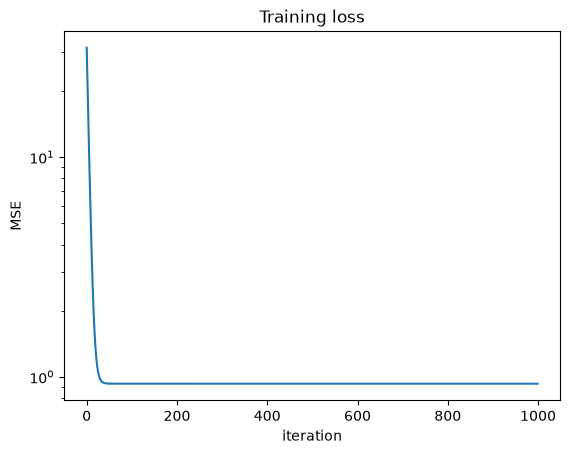

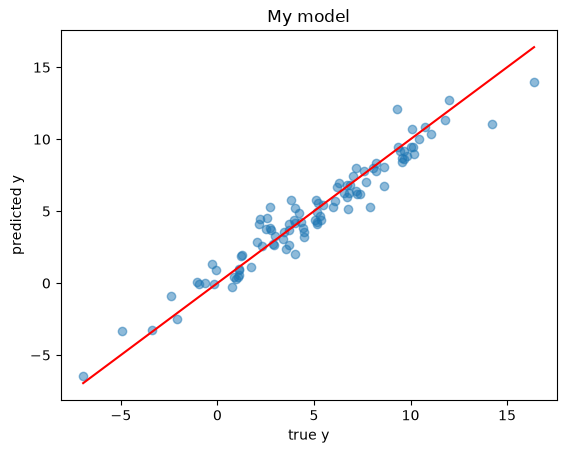

In [4]:
my_model = MyLinearRegression().fit(X_train, y_train)
my_pred = my_model.predict(X_test)
my_mse = mean_squared_error(y_test, my_pred)

print(f"My MSE: {my_mse:.3f}")

plt.plot(my_model.losses)
plt.yscale("log")
plt.xlabel("iteration")
plt.ylabel("MSE")
plt.title("Training loss")
plt.show()

plot_predictions(y_test, my_pred, "My model")

## Comparison with scikit-learn

The same data, the reference `LinearRegression`. The table shows the parameters and the error of each model.

true:     w=[ 3.  -2.   0.5]       b=4.000
mine:     w=[ 2.929 -2.032  0.477] b=4.026  MSE=1.102
sklearn:  w=[ 2.929 -2.032  0.477] b=4.026  MSE=1.102
Max weight difference: 8.88e-15


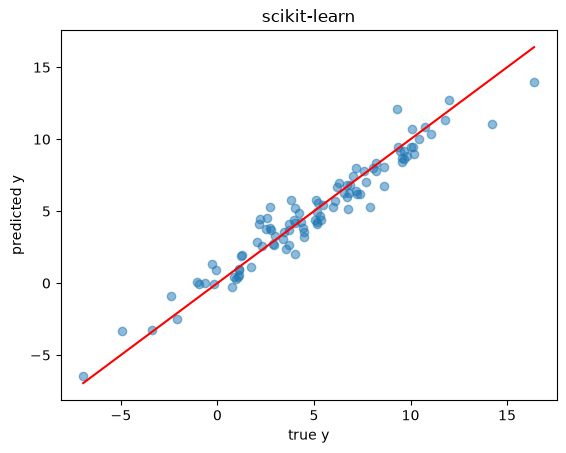

In [5]:
sk_model = LinearRegression().fit(X_train, y_train)
sk_pred = sk_model.predict(X_test)
sk_mse = mean_squared_error(y_test, sk_pred)

print(f"true:     w={TRUE_W}       b={TRUE_B:.3f}")
print(f"mine:     w={my_model.w.round(3)} b={my_model.b:.3f}  MSE={my_mse:.3f}")
print(f"sklearn:  w={sk_model.coef_.round(3)} b={sk_model.intercept_:.3f}  MSE={sk_mse:.3f}")
print(f"Max weight difference: {np.abs(my_model.w - sk_model.coef_).max():.2e}")

plot_predictions(y_test, sk_pred, "scikit-learn")

## Takeaways

- My model beats the baseline (1.102 vs. 16.922) and matches scikit-learn.
- The learned parameters are close to the true ones. The remaining error comes from the noise.
- Not covered yet: feature scaling and regularization.